# Broadband flow
$$p(z | x) \approx q_\phi(z | x)$$
Flow to infer redshift given broadband photometry. 
The flow is trained on spectroscopic redshift and broadband LSST-like photometry $x$ (CFHT u + HSC grizy degraded to match LSST noise levels)

In [1]:
import copy
import torch
import numpy as np
import matplotlib.pyplot as plt
# - nflows - 
from nflows.flows.base import Flow
from nflows.distributions.normal import StandardNormal
from nflows.transforms.base import CompositeTransform
from nflows.transforms.autoregressive import MaskedPiecewiseRationalQuadraticAutoregressiveTransform

In [2]:
seed = 20261024
flow_seeds = [seed + i for i in range(5)]
epochs = 200
max_steps = 20000

In [3]:
plt.rcParams.update(
    {
        'font.family': 'serif',
        'font.size': 11,
        'axes.linewidth': 1.5,
        'xtick.major.size': 5,
        'ytick.major.size': 5,
        'xtick.major.width': 1.5,
        'ytick.major.width': 1.5,
        'legend.frameon': False,
    }
)

## 2. Load the data and preserve the spatial split
Fluxes and errors are in microJy, ordered u, g, r, i, z, y, with shape (N, 6).
`native_flux` is the deep measurement; `sigma_added` is the extra noise standard
deviation needed for the target depth. The saved `flux` is one fixed degraded
realization used for validation and testing. We do not add noise to it again.
The split is spatial: 0 = training, 1 = validation, 2 = test.

In [4]:
keys = [
    'id',
    'native_flux',
    'flux',
    'fluxerr',
    'sigma_added',
    'zspec',
    'has_specz',
    'split',
    'imag',
    'cell',
]

with np.load('../data/parent.npz') as f:
    data = {key: f[key] for key in keys}

assert data['flux'].shape == data['fluxerr'].shape == (len(data['id']), 6)
assert np.isfinite(data['flux']).all() and np.isfinite(data['native_flux']).all()
assert np.isfinite(data['fluxerr']).all() and (data['fluxerr'] > 0).all()
assert np.isfinite(data['sigma_added']).all() and (data['sigma_added'] >= 0).all()
assert len(np.unique(data['id'])) == len(data['id'])
for a, b in [(0, 1), (0, 2), (1, 2)]:
    assert not np.intersect1d(
        data['cell'][data['split'] == a], data['cell'][data['split'] == b]
    ).size
spec = data['has_specz']
assert np.all((data['zspec'][spec] > 0) & (data['zspec'][spec] < 10))

## 3. Normalize the broadband photometry and uncertainties

Each context has 12 features: six asinh magnitude features (defined for negative
fluxes) and six log errors. Match `train_flows.py`: estimate means and scales
from the **full photometric training split**, without using any redshift labels.
Both flow demos use this same normalization, even though their labeled samples differ.

In [5]:
def raw_features(flux, err):
    # Asinh magnitudes remain defined for negative fluxes and nondetections.
    # Log errors let the flow distinguish measurements with different precision.
    soft = 0.02  # microJy; fixed and independent of labels
    lupt = 23.9 - (2.5 / np.log(10)) * (np.arcsinh(flux / (2 * soft)) + np.log(soft))
    return np.c_[lupt, np.log(np.maximum(err, 1e-7) / soft)].astype(np.float32)

phot_train = (data['split'] == 0) # training data
features = raw_features(data['native_flux'][phot_train], data['fluxerr'][phot_train])
mean = features.mean(axis=0)
scale = np.maximum(features.std(axis=0), 0.1)

## 4. Select training and validation
Select a fixed subset of up to 4,096 validation galaxies using the training seed.
Fixed validation photometry and labels let us compare losses across epochs.
The held-out test set never selects an epoch or a hyperparameter.
Use the same validation photometry and labels for all five flows.
Select the best epoch and flow using validation loss only.

In [6]:
train = np.flatnonzero((data['split'] == 0) & np.isfinite(data['zspec']))
valid = np.flatnonzero((data['split'] == 1) & np.isfinite(data['zspec']))

rng = np.random.default_rng(seed)
vi = rng.choice(valid, min(len(valid), 4096), replace=False)
vy = data['zspec'][vi].astype(np.float32)
print(f'Training: {len(train):,}; validation: {len(valid):,} galaxies')
print(f'Fixed validation labels: {len(vy):,} secure redshifts')

Training: 22,604; validation: 4,803 galaxies
Fixed validation labels: 4,096 secure redshifts


## 5. Define the flow
Transform redshift to a scaled-logit variable $t$. Each run initializes a fresh
flow with the same architecture and its own optimizer and learning-rate scheduler.

In [7]:
def z_to_t(z):
    # Map the finite COSMOS support (0, 10) to the real line with a scaled logit.
    # Clipping avoids divergent logits at the grid endpoints.
    z = torch.clamp(z, 1e-5, 10 - 1e-5)
    return (torch.log(z / (10 - z)) + 2.2) / 1.1

def t_to_z(t):
    # Invert the redshift logit to return predictions in physical redshift units.
    return 10 * torch.sigmoid(t * 1.1 - 2.2)

def context(flux, err, mean, scale):
    # Apply training-only feature scaling; clipping limits extreme input values.
    return torch.from_numpy(np.clip((raw_features(flux, err) - mean) / scale, -12, 12).astype(np.float32))

vx = context(data['flux'][vi], data['fluxerr'][vi], mean, scale)
vt = z_to_t(torch.from_numpy(vy[:, None]))

In [8]:
def make_flow(context_features=12):
    # Two conditional spline transforms map redshift to a standard normal.
    # The context comprises six broadband flux features and six error features.
    transforms = [
        MaskedPiecewiseRationalQuadraticAutoregressiveTransform(
            features=1,
            hidden_features=64,
            context_features=context_features,
            num_bins=16,
            tails='linear',
            tail_bound=5.0,
            num_blocks=2,
            dropout_probability=0.0,
            use_batch_norm=False,
        )
        for _ in range(2)
    ]
    return Flow(CompositeTransform(transforms), StandardNormal([1]))

## 6. Train five flows and select the best
Train five independent seeds on the same training sample. Every batch starts
from native fluxes and draws the missing noise variance. Each run uses batches
of 512, gradient clipping at 5, and learning-rate reduction on a validation plateau.
Stop a run after eight epochs without an improvement of at least 1e-4, or at its
epoch/step limit. Keep its lowest-loss epoch, then select the lowest-loss flow.
Validation loss is a density in transformed $t$; test labels never select a model.

In [9]:
best = float('inf')
best_state = None
runs = []

for run_seed in flow_seeds:
    torch.manual_seed(run_seed)
    rng = np.random.default_rng(run_seed)
    train_order = train.copy()
    model = make_flow()
    opt = torch.optim.AdamW(model.parameters(), lr=8e-4, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=3, factor=0.5)
    run_best = float('inf')
    stopping_best = float('inf')
    run_state = None
    bad = 0
    step = 0
    history = []
    for epoch in range(epochs):
        model.train()
        rng.shuffle(train_order)
        losses = []
        for pos in range(0, len(train), 512):
            idx = train_order[pos : pos + 512]
            noise = rng.normal(size=(len(idx), 6)).astype(np.float32)
            xflux = data['native_flux'][idx] + noise * data['sigma_added'][idx]
            x = context(xflux, data['fluxerr'][idx], mean, scale)
            z = data['zspec'][idx].astype(np.float32)
            target = z_to_t(torch.from_numpy(z[:, None]))

            opt.zero_grad(set_to_none=True)
            loss = -model.log_prob(target, context=x).mean()
            if not torch.isfinite(loss):
                raise RuntimeError('Nonfinite training loss')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            losses.append(float(loss.detach()))
            step += 1
            if step >= max_steps:
                break

        model.eval()
        with torch.no_grad():
            vals = [
                -model.log_prob(vt[p : p + 1024], context=vx[p : p + 1024]).sum().item()
                for p in range(0, len(vt), 1024)
            ]
            val = sum(vals) / len(vt)
        if not np.isfinite(val):
            raise RuntimeError('Nonfinite validation loss')
        scheduler.step(val)
        history.append(
            {
                'epoch': epoch + 1,
                'step': step,
                'train_loss': float(np.mean(losses)),
                'validation_loss': val,
            }
        )
        print(f'Seed {run_seed}; epoch {epoch + 1}; train {np.mean(losses):.4f}; val {val:.4f}')
        if val < run_best:
            run_best = val
            run_state = copy.deepcopy(model.state_dict())
            run_epoch = epoch + 1
        if val < stopping_best - 1e-4:
            stopping_best = val
            bad = 0
        else:
            bad += 1
        if bad >= 8 or step >= max_steps:
            break

    assert run_state is not None
    runs.append({
        'seed': run_seed,
        'best_validation_loss': run_best,
        'best_epoch': run_epoch,
        'history': history,
    })
    if run_best < best:
        best = run_best
        best_state = run_state
        best_seed = run_seed
        best_epoch = run_epoch
    print(f'Seed {run_seed}: best validation loss {run_best:.4f} at epoch {run_epoch}')

assert best_state is not None
model.load_state_dict(best_state)
model.eval()
print(f'Selected seed {best_seed}, epoch {best_epoch}: validation loss {best:.4f}')

Seed 20261024; epoch 1; train 0.9839; val 0.3869
Seed 20261024; epoch 2; train 0.1037; val -0.0968
Seed 20261024; epoch 3; train -0.1389; val -0.1873
Seed 20261024; epoch 4; train -0.1838; val -0.2873
Seed 20261024; epoch 5; train -0.2780; val -0.3912
Seed 20261024; epoch 6; train -0.3053; val -0.2716
Seed 20261024; epoch 7; train -0.2845; val -0.3658
Seed 20261024; epoch 8; train -0.3457; val -0.3654
Seed 20261024; epoch 9; train -0.3796; val -0.4215
Seed 20261024; epoch 10; train -0.4126; val -0.4481
Seed 20261024; epoch 11; train -0.4444; val -0.4533
Seed 20261024; epoch 12; train -0.4750; val -0.5202
Seed 20261024; epoch 13; train -0.4932; val -0.6091
Seed 20261024; epoch 14; train -0.5759; val -0.6750
Seed 20261024; epoch 15; train -0.6739; val -0.7181
Seed 20261024; epoch 16; train -0.6302; val -0.5844
Seed 20261024; epoch 17; train -0.7015; val -0.6478
Seed 20261024; epoch 18; train -0.7215; val -0.5727
Seed 20261024; epoch 19; train -0.7114; val -0.7964
Seed 20261024; epoch 20;

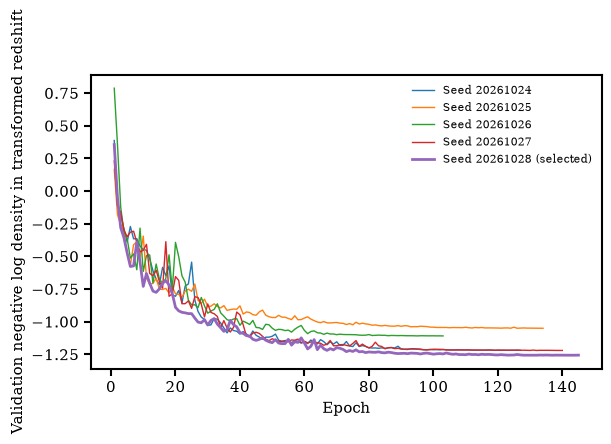

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
for run in runs:
    history = run['history']
    selected = run['seed'] == best_seed
    label = f'Seed {run["seed"]}' + (' (selected)' if selected else '')
    ax.plot(
        [row['epoch'] for row in history],
        [row['validation_loss'] for row in history],
        lw=2 if selected else 1,
        label=label,
    )
ax.set(xlabel='Epoch', ylabel='Validation negative log density in transformed redshift')
ax.legend(fontsize=8)
plt.show()

## 7. Apply flow to test photometry
Apply it to the **full photometric test split**, including galaxies without
spectroscopy. We only restrict to secure spectra later when evaluating accuracy.

In [11]:
@torch.no_grad()
def predict_quantiles(model, flux, err, mean, scale, batch_size=512):
    # Return five redshift quantiles for each six-band flux/error row.
    probs = torch.tensor([0.025, 0.16, 0.5, 0.84, 0.975])
    normal_q = torch.distributions.Normal(0.0, 1.0).icdf(probs)
    prediction = []
    for start in range(0, len(flux), batch_size):
        x = context(flux[start : start + batch_size], err[start : start + batch_size], mean, scale)
        t, _ = model._transform.inverse(
            normal_q.repeat(len(x)).reshape(-1, 1),
            context=x.repeat_interleave(5, dim=0),
        )
        prediction.append(t_to_z(t).reshape(len(x), 5).numpy())
    return np.concatenate(prediction)

phot_test = np.flatnonzero(data['split'] == 2)
q_all = predict_quantiles(model, data['flux'][phot_test], data['fluxerr'][phot_test], mean, scale)
print(f'Predicted {len(phot_test):,} test galaxies without using redshift labels')

Predicted 26,635 test galaxies without using redshift labels


## 8. Evaluate flow where independent test spectroscopy is available

In [12]:
scored = data['has_specz'][phot_test]
test = phot_test[scored]
ztest = data['zspec'][test]
q = q_all[scored]
ctx = context(data['flux'][test], data['fluxerr'][test], mean, scale)

[(0.0, 5.0),
 (0.0, 5.0),
 Text(0.5, 0, '$z_{\\mathrm{spec}}$'),
 Text(0, 0.5, 'Median $z$')]

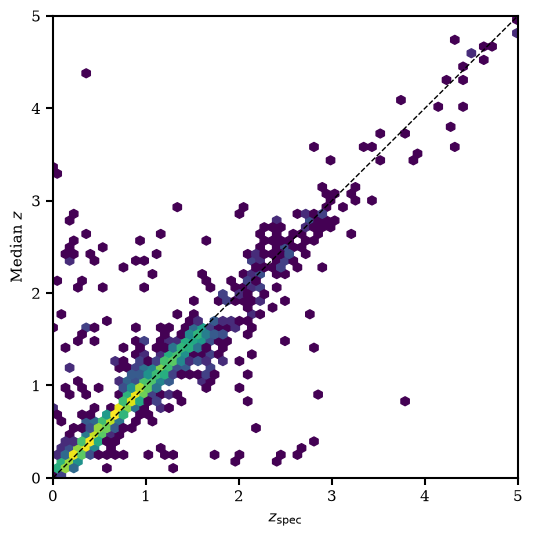

In [13]:
fig = plt.figure(figsize=(6,6))
sub = fig.add_subplot(111)
sub.hexbin(ztest, q[:, 2], gridsize=60, bins='log', mincnt=1, cmap='viridis')
sub.plot([0, 5], [0, 5], 'k--', lw=1)
sub.set(xlim=(0, 5), ylim=(0, 5), xlabel=r'$z_{\mathrm{spec}}$', ylabel=r'Median $z$')

In [14]:
@torch.no_grad()
def log_prob_z(model, z, ctx):
    z = torch.as_tensor(z, dtype=torch.float32).reshape(-1, 1)
    w = z_to_t(z)
    # The flow density is in transformed t; add log|dt/dz| to obtain p(z | x).
    jac = np.log(10) - torch.log(z) - torch.log(10 - z) - np.log(1.1)
    return model.log_prob(w, context=ctx) + jac[:, 0]

@torch.no_grad()
def posterior_summary(model, ctx, zspec):
    # Invert standard-normal quantiles rather than estimate intervals from samples.
    probs = torch.tensor([0.025, 0.16, 0.5, 0.84, 0.975])
    noise = torch.distributions.Normal(0.0, 1.0).icdf(probs)
    quant = []
    pit = []
    nll = []
    for start in range(0, len(ctx), 512):
        x = ctx[start : start + 512]
        n = len(x)
        q, _ = model._transform.inverse(
            noise.repeat(n).reshape(-1, 1), context=x.repeat_interleave(5, dim=0)
        )
        quant.append(t_to_z(q).reshape(n, 5).numpy())
        z = torch.tensor(zspec[start : start + 512], dtype=torch.float32).reshape(-1, 1)
        # The base-normal CDF gives the posterior rank (PIT) of the true spec-z.
        u, _ = model._transform(z_to_t(z), context=x)
        pit.append((0.5 * (1 + torch.erf(u[:, 0] / np.sqrt(2)))).numpy())
        nll.append((-log_prob_z(model, z, x)).numpy())
    return np.concatenate(quant), np.concatenate(pit), np.concatenate(nll)

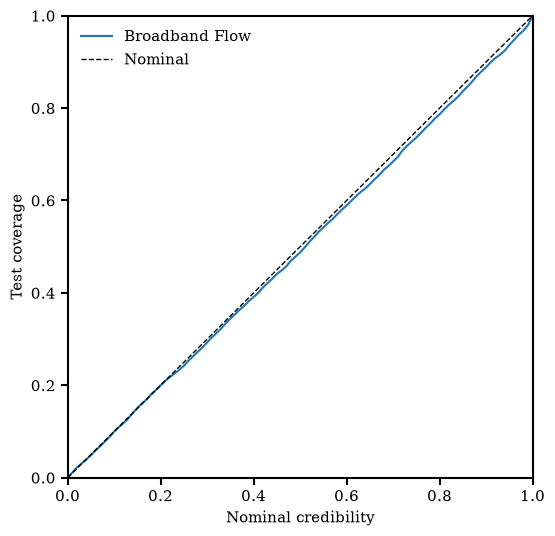

In [15]:
q_check, pit, nll = posterior_summary(model, ctx, ztest)


credibility = np.linspace(0, 1, 101)
rank = np.abs(2 * pit - 1)
curve = np.array([(rank <= level).mean() for level in credibility])
curve[0], curve[-1] = 0, 1

fig = plt.figure(figsize=(6,6))
sub = fig.add_subplot(111)
sub.plot(credibility, curve, label='Broadband Flow')
sub.plot([0, 1], [0, 1], 'k--', lw=1, label='Nominal')
sub.set(xlim=(0, 1), ylim=(0, 1), xlabel='Nominal credibility', ylabel='Test coverage')
sub.legend()
plt.show()

Example PDFs below use `log_prob_z`, including the redshift Jacobian.
Examples span the spectroscopic test sample's native i-band magnitudes.
Dashed lines show test spectroscopy for evaluation only.

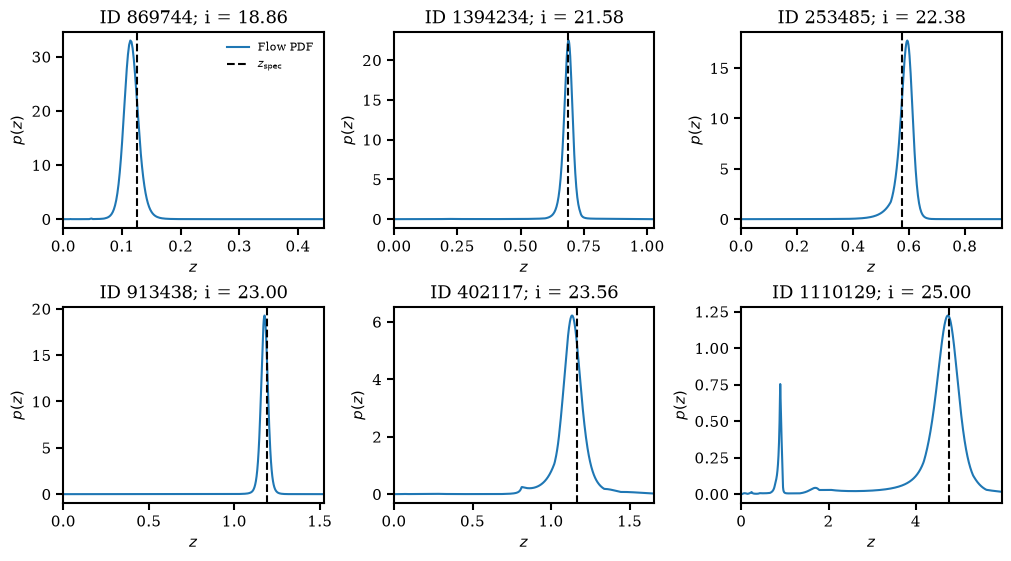

In [16]:
order = np.argsort(data['imag'][test])
examples = order[np.linspace(0, len(order) - 1, 6, dtype=int)]
zgrid = np.linspace(1e-4, 10 - 1e-4, 5001, dtype=np.float32)
fig, axes = plt.subplots(2, 3, figsize=(10, 5.5), constrained_layout=True)
for ax, j in zip(axes.flat, examples):
    x = ctx[j : j + 1].repeat(len(zgrid), 1)
    pdf = np.exp(log_prob_z(model, zgrid, x).numpy())
    assert np.isfinite(pdf).all() and (pdf >= 0).all()
    ax.plot(zgrid, pdf, label='Flow PDF')
    ax.axvline(ztest[j], color='k', ls='--', label=r'$z_{\mathrm{spec}}$')
    ax.set(xlim=(0, min(10, max(q[j, 4], ztest[j]) + 0.3)), xlabel=r'$z$', ylabel=r'$p(z)$')
    ax.set_title(f'ID {data["id"][test[j]]}; i = {data["imag"][test[j]]:.2f}')
axes.flat[0].legend(fontsize=8)
plt.show()

## 9. Save the selected flow and its predictions
Save the best flow with its seed, validation loss, and all five training histories.
Prediction filenames and fields remain compatible with `paper_comparison.ipynb`.

In [17]:
checkpoint = {
    'state_dict': best_state,
    'feature_mean': mean,
    'feature_scale': scale,
    'model': 'two conditional RQS autoregressive transforms; 16 bins; hidden64; blocks2',
    'n_train': len(train),
    'n_validation': len(valid),
    'seed': best_seed,
    'validation_seed': seed,
    'best_epoch': best_epoch,
    'best_validation_loss': best,
    'flow_seeds': flow_seeds,
    'runs': runs,
}
torch.save(checkpoint, '../data/broadband_flow.pt')

prediction = {key: data[key][test] for key in ['id', 'zspec', 'imag', 'flux', 'fluxerr']}
prediction.update({'quantiles': q, 'pit': pit, 'nll': nll})
np.savez_compressed(
    '../data/broadband_flow_test_predictions.npz', **prediction)